# 08 · Character-level deep learning: char-CNN and BiLSTM (Milestone 4)

The char n-gram model beat XGBoost on every URL view (notebook 07), because the signal is in the **characters** (`.cf`, `paypa1`, random strings), which our 40 count features lose. Deep models read the characters directly and can learn their own patterns:

| Model | How it reads a URL |
|---|---|
| **Char-CNN** | Filters of width 3–6 slide over the URL, each firing on a learned character pattern (like a learned n-gram). It keeps each filter's strongest match anywhere in the URL. |
| **BiLSTM** | Reads the URL left→right and right→left, carrying a memory, so each character is seen in the context of the whole URL. |

Code: `src/phishguard/deep.py`. Both are wrapped as scikit-learn-style estimators, so `experiment.run()` treats them exactly like every earlier model: 5 splits, tune on validation log-loss, threshold on validation, test once.

**Reporting protocol (fixed before running, `docs/DECISIONS.md`):** raw URL, domain only and registered domain; mean ± sd over 5 splits; seed-42 95% CI; McNemar test against the char n-gram model on the same view. Nothing is dropped if it looks bad.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import numpy as np
import pandas as pd
import torch

from phishguard.data import load_clean, TARGET
from phishguard.urls import URL_VIEWS
from phishguard.deep import CharURLClassifier, CharVocab, CharCNN, BiLSTM, pick_device
from phishguard.evaluate import load_results, precision_at_base_rate
from phishguard.experiment import run, summary_table, load_predictions
from phishguard.modeling import param_grid
from phishguard.stats import mcnemar

df = load_clean()
y = df[TARGET]
VIEWS = ["raw URL", "domain only", "registered domain"]
print("torch", torch.__version__, "| device:", pick_device())

torch 2.14.1 | device: mps


## 1. From characters to numbers

A neural network needs numbers. Each character gets an id (`CharVocab`, built on **training URLs only**). Rare characters share the id `UNK` = 1, and `PAD` = 0 fills shorter URLs up to the batch length. Every id then becomes a learned vector of 32 numbers (an **embedding**).

In [2]:
vocab = CharVocab().fit(df["URL"])          # for illustration only; inside fit() it is built on train
ids, lengths = vocab.encode(pd.Series(["https://www.paypa1.top", "ipfs.io"]), max_len=24)
print(len(vocab), "ids (incl. PAD and UNK)")
pd.DataFrame(ids, index=["https://www.paypa1.top", "ipfs.io"])

61 ids (incl. PAD and UNK)


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
https://www.paypa1.top,40,52,52,48,51,25,14,14,55,55,...,57,48,33,16,13,52,47,48,0,0
ipfs.io,41,48,38,51,13,41,47,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
for name, net in {"Char-CNN": CharCNN(len(vocab)), "BiLSTM": BiLSTM(len(vocab))}.items():
    print(f"{name}: {sum(p.numel() for p in net.parameters()):,} trainable weights")
    print(net, end="\n\n")

Char-CNN: 141,985 trainable weights
CharCNN(
  (embed): Embedding(61, 32, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(32, 128, kernel_size=(3,), stride=(1,))
    (1): Conv1d(32, 128, kernel_size=(4,), stride=(1,))
    (2): Conv1d(32, 128, kernel_size=(5,), stride=(1,))
    (3): Conv1d(32, 128, kernel_size=(6,), stride=(1,))
  )
  (head): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)

BiLSTM: 60,449 trainable weights
BiLSTM(
  (embed): Embedding(61, 32, padding_idx=0)
  (lstm): LSTM(32, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)



## 2. Training choices (decision D12)

- **Loss:** binary cross-entropy (= log-loss), optimiser Adam, learning rate 0.001, batches of 256 URLs of similar length (so little time is spent on padding).
- **Early stopping:** `fit()` holds out 10% of the *training* site owners. After every epoch we measure log-loss there and keep the best epoch's weights (stop after 2 epochs without improvement, at most 15). The real validation split stays untouched for tuning and the threshold.
- **Tuning:** dropout ∈ {0.3, 0.5}, the amount of regularisation, chosen on validation log-loss for each split.
- **Input:** lowercased, cut at 200 characters (99.5% of URLs are shorter).
- **Hardware:** Apple GPU (MPS). GPU arithmetic isn't bit-for-bit reproducible, so a re-run can differ in the last decimal.

## 3. Both models on the three views, 5 splits each (~1–2 hours)

In [4]:
make_cnn = lambda dropout: CharURLClassifier(arch="cnn", dropout=dropout)
make_bilstm = lambda dropout: CharURLClassifier(arch="bilstm", dropout=dropout)
grid = param_grid(dropout=[0.3, 0.5])

experiments = {}
for view in VIEWS:
    urls = URL_VIEWS[view](df["URL"])
    for model_name, make_model in {"Char-CNN": make_cnn, "BiLSTM": make_bilstm}.items():
        experiments[(view, model_name)] = run(f"{model_name} | {view}", make_model, grid, urls, y, df,
                                              features=view, group="m4_deep")
        exp = experiments[(view, model_name)]
        print(f"{model_name:9s} | {view:17s} {exp.summary.loc['accuracy', 'mean']:.2%} ± "
              f"{exp.summary.loc['accuracy', 'sd']:.2%}   (seed-42 best epoch {exp.reference.model.best_epoch_})")
summary_table(experiments.values())

Char-CNN  | raw URL           99.68% ± 0.03%   (seed-42 best epoch 4)


BiLSTM    | raw URL           99.68% ± 0.04%   (seed-42 best epoch 7)


Char-CNN  | domain only       86.58% ± 0.92%   (seed-42 best epoch 11)


BiLSTM    | domain only       85.55% ± 1.35%   (seed-42 best epoch 11)


Char-CNN  | registered domain 80.85% ± 1.53%   (seed-42 best epoch 4)


BiLSTM    | registered domain 80.95% ± 0.62%   (seed-42 best epoch 4)


,accuracy (%),f1 (%),roc_auc,pr_auc,mcc,tpr_at_fpr_1pct (%),"accuracy, seed 42 [95% CI]"
model,,,,,,,
Char-CNN | raw URL,99.68 ± 0.03,99.62 ± 0.04,0.9982 ± 0.0002,0.9985 ± 0.0002,0.9935 ± 0.0006,99.46 ± 0.06,"99.73% [99.66%, 99.78%]"
BiLSTM | raw URL,99.68 ± 0.04,99.62 ± 0.05,0.9981 ± 0.0004,0.9984 ± 0.0003,0.9934 ± 0.0008,99.44 ± 0.08,"99.74% [99.68%, 99.79%]"
Char-CNN | domain only,86.58 ± 0.92,82.09 ± 1.40,0.9165 ± 0.0062,0.9205 ± 0.0062,0.7319 ± 0.0182,65.33 ± 1.81,"87.83% [86.83%, 89.06%]"
BiLSTM | domain only,85.55 ± 1.35,80.34 ± 2.22,0.9093 ± 0.0109,0.9141 ± 0.0104,0.7135 ± 0.0256,65.97 ± 3.68,"87.21% [85.88%, 88.57%]"
Char-CNN | registered domain,80.85 ± 1.53,73.24 ± 3.17,0.8793 ± 0.0092,0.8753 ± 0.0089,0.6154 ± 0.0268,47.20 ± 2.56,"83.14% [81.21%, 85.04%]"
BiLSTM | registered domain,80.95 ± 0.62,73.97 ± 1.80,0.8678 ± 0.0094,0.8671 ± 0.0083,0.6143 ± 0.0107,46.39 ± 3.67,"81.90% [79.94%, 83.91%]"


## 4. Compared with the Milestone 3 models (same splits, same views)

In [5]:
earlier = load_results("m3_views")
deep = load_results("m4_deep")
both = pd.concat([earlier, deep])
both["view"] = both["model"].str.split(" \\| ").str[1]
both["family"] = both["model"].str.split(" \\| ").str[0].replace({"XGBoost URL features": "XGBoost (URL features)"})
both = both[both["view"].isin(VIEWS)]

table = both.pivot(index="family", columns="view", values="accuracy")[VIEWS].mul(100)
sd = both.pivot(index="family", columns="view", values="accuracy_sd")[VIEWS].mul(100)
(table.round(2).astype(str) + " ± " + sd.round(2).astype(str)).loc[
    ["Char n-gram LogReg", "XGBoost (URL features)", "Char-CNN", "BiLSTM"]]

view,raw URL,domain only,registered domain
family,,,
Char n-gram LogReg,99.7 ± 0.03,86.27 ± 0.89,82.49 ± 1.93
XGBoost (URL features),99.64 ± 0.03,81.43 ± 1.15,72.82 ± 0.7
Char-CNN,99.68 ± 0.03,86.58 ± 0.92,80.85 ± 1.53
BiLSTM,99.68 ± 0.04,85.55 ± 1.35,80.95 ± 0.62


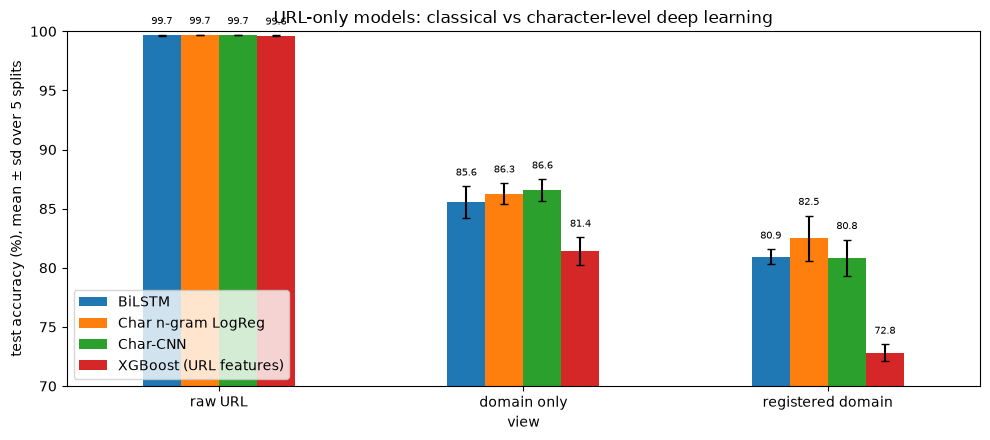

In [6]:
ax = table.T.plot.bar(yerr=sd.T, capsize=3, figsize=(10, 4.5), rot=0)
ax.set_ylim(70, 100)
ax.set_ylabel("test accuracy (%), mean ± sd over 5 splits")
ax.set_title("URL-only models: classical vs character-level deep learning")
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt="%.1f", fontsize=7, padding=6)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [7]:
cols = ["roc_auc", "pr_auc", "mcc", "tpr_at_fpr_1pct", "brier"]
both.set_index(["view", "family"]).loc[VIEWS, cols].sort_index(level=0, sort_remaining=False).round(4)

roc_auc  pr_auc     mcc  \
view              family                                            
domain only       Char n-gram LogReg       0.9162  0.9194  0.7233   
                  XGBoost (URL features)   0.8473  0.8613  0.6296   
                  Char-CNN                 0.9165  0.9205  0.7319   
                  BiLSTM                   0.9093  0.9141  0.7135   
raw URL           Char n-gram LogReg       0.9985  0.9988  0.9938   
                  XGBoost (URL features)   0.9972  0.9979  0.9927   
                  Char-CNN                 0.9982  0.9985  0.9935   
                  BiLSTM                   0.9981  0.9984  0.9934   
registered domain Char n-gram LogReg       0.8945  0.8934  0.6490   
                  XGBoost (URL features)   0.7698  0.7697  0.4644   
                  BiLSTM                   0.8678  0.8671  0.6143   
                  Char-CNN                 0.8793  0.8753  0.6154   

                                          tpr_at_fpr_1pct   brier  
view              family                                           
domain only       Char n-gram LogReg               0.6385  0.1029  
                  XGBoost (URL features)           0.5459  0.1362  
                  Char-CNN                         0.6533  0.1007  
                  BiLSTM                           0.6597  0.1053  
raw URL           Char n-gram LogReg               0.9953  0.0032  
                  XGBoost (URL features)           0.9935  0.0034  
                  Char-CNN                         0.9946  0.0030  
                  BiLSTM                           0.9944  0.0031  
registered domain Char n-gram LogReg               0.5292  0.1236  
                  XGBoost (URL features)           0.3434  0.1805  
                  BiLSTM                           0.4639  0.1379  
                  Char-CNN                         0.4720  0.1357

## 5. Is the deep model really better than the n-gram model? (McNemar, seed-42 test split)

Same test URLs for both models. We count the URLs where exactly one of them is right.

In [8]:
rows = []
for view in VIEWS:
    ngram = load_predictions("m3_views", f"Char n-gram LogReg | {view}")
    ngram_right = (ngram["test_prob"] >= ngram["threshold"]) == y.loc[ngram["test_idx"]].to_numpy()
    for model_name in ["Char-CNN", "BiLSTM"]:
        deep_pred = load_predictions("m4_deep", f"{model_name} | {view}")
        assert (deep_pred["test_idx"] == ngram["test_idx"]).all()
        deep_right = (deep_pred["test_prob"] >= deep_pred["threshold"]) == y.loc[deep_pred["test_idx"]].to_numpy()
        rows.append({"view": view, "A vs B": f"{model_name} vs n-gram", **mcnemar(deep_right, ngram_right)})
for view in VIEWS:
    a, b = (load_predictions("m4_deep", f"{m} | {view}") for m in ["Char-CNN", "BiLSTM"])
    yt = y.loc[a["test_idx"]].to_numpy()
    rows.append({"view": view, "A vs B": "Char-CNN vs BiLSTM",
                 **mcnemar((a["test_prob"] >= a["threshold"]) == yt, (b["test_prob"] >= b["threshold"]) == yt)})
mc = pd.DataFrame(rows).rename(columns={"only_a_right": "only A right", "only_b_right": "only B right"})
mc["verdict (p < 0.05)"] = np.where(mc["p_value"] < 0.05,
                                    np.where(mc["only A right"] > mc["only B right"], "A better", "B better"),
                                    "no difference")
mc.round({"p_value": 4})

,view,A vs B,only A right,only B right,p_value,verdict (p < 0.05)
0,raw URL,Char-CNN vs n-gram,11,20,0.1496,no difference
1,raw URL,BiLSTM vs n-gram,13,18,0.4731,no difference
2,domain only,Char-CNN vs n-gram,1074,898,0.0001,A better
3,domain only,BiLSTM vs n-gram,1123,1164,0.4029,no difference
4,registered domain,Char-CNN vs n-gram,1065,1729,0.0000,B better
5,registered domain,BiLSTM vs n-gram,1346,2445,0.0000,B better
6,raw URL,Char-CNN vs BiLSTM,9,13,0.5235,no difference
7,domain only,Char-CNN vs BiLSTM,894,677,0.0000,A better
8,registered domain,Char-CNN vs BiLSTM,1715,1280,0.0000,A better


## 6. How training went (seed-42 split, selected setting)

`train_loss` falls every epoch. The early-stopping loss (held-out training owners) stops improving after a few epochs, and that is where the weights are kept.

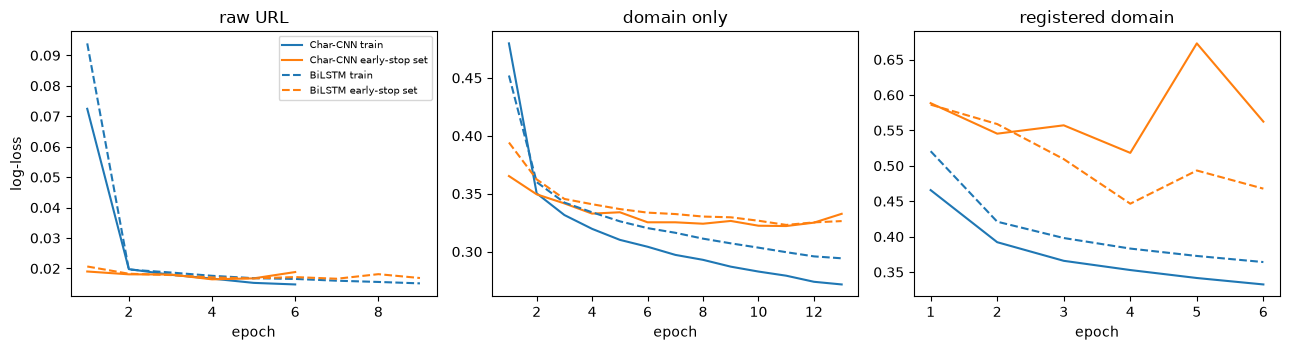

,view,model,dropout,best epoch,seconds per epoch
0,raw URL,Char-CNN,0.3,4,9.983333
1,raw URL,BiLSTM,0.3,7,23.944444
2,domain only,Char-CNN,0.3,11,8.169231
3,domain only,BiLSTM,0.3,11,13.361538
4,registered domain,Char-CNN,0.3,4,8.533333
5,registered domain,BiLSTM,0.3,4,9.716667


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, view in zip(axes, VIEWS):
    for model_name, style in [("Char-CNN", "-"), ("BiLSTM", "--")]:
        history = pd.DataFrame(experiments[(view, model_name)].reference.model.history_)
        ax.plot(history["epoch"], history["train_loss"], style, color="tab:blue", label=f"{model_name} train")
        ax.plot(history["epoch"], history["stop_loss"], style, color="tab:orange", label=f"{model_name} early-stop set")
    ax.set_title(view)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("log-loss")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
pd.DataFrame([{"view": v, "model": m, "dropout": e.reference.model.arch_options["dropout"],
               "best epoch": e.reference.model.best_epoch_,
               "seconds per epoch": np.mean([h["seconds"] for h in e.reference.model.history_])}
              for (v, m), e in experiments.items()])

## 7. Where do the char-CNN and the n-gram model disagree? (domain only, seed-42 test)

In [10]:
view = "domain only"
cnn, ngram = load_predictions("m4_deep", f"Char-CNN | {view}"), load_predictions("m3_views", f"Char n-gram LogReg | {view}")
test_idx = cnn["test_idx"]
domains = URL_VIEWS[view](df["URL"]).loc[test_idx].to_numpy()
yt = y.loc[test_idx].to_numpy()
cnn_right = (cnn["test_prob"] >= cnn["threshold"]) == yt
ngram_right = (ngram["test_prob"] >= ngram["threshold"]) == yt
label = np.where(yt == 1, "phishing", "legitimate")
pd.DataFrame({
    "only the CNN right": pd.Series(domains[cnn_right & ~ngram_right] + "  (" + label[cnn_right & ~ngram_right] + ")").head(12),
    "only the n-gram right": pd.Series(domains[~cnn_right & ngram_right] + "  (" + label[~cnn_right & ngram_right] + ")").head(12),
    "both wrong": pd.Series(domains[~cnn_right & ~ngram_right] + "  (" + label[~cnn_right & ~ngram_right] + ")").head(12),
})

,only the CNN right,only the n-gram right,both wrong
0,usbirthcertificates.com (legitimate),c.line-design.fr (legitimate),aresync.com (phishing)
1,hostmaster.ua (legitimate),tradeadspace.info (phishing),constructiongst.com (phishing)
2,ianacurtis.rmxcontabilidade.com.br (phishing),chieuphan-bdshotram.com (phishing),wp-amazon-plugin.com (legitimate)
3,fatura-sorgu.com (phishing),coincube.io (phishing),stmfl.com (phishing)
4,shop.woodfermliving.com (phishing),hostpapa.com (legitimate),walemi.com (phishing)
5,ganymed.beeppool.org (phishing),clientcentre.net (phishing),onlinequranteaching.com (phishing)
6,jnlklknlknlk.agilecrm.com (phishing),es.catholic.net (legitimate),unboxed.co (legitimate)
7,nogiledeneli.ru (phishing),mail-king.com (phishing),frissoncourier.com (phishing)
8,thor.blocktrail.com (phishing),hotel-mssngr.com (legitimate),glassesofwine.com (phishing)
9,hanbit.co.kr (legitimate),minsal.cl (legitimate),whoer.net (phishing)


## 8. What the numbers mean in real traffic

Precision if only 1% or 0.1% of visited URLs were phishing (same recall and false-alarm rate as on the test split; mean over the 5 splits).

In [11]:
rows = []
for (view, model_name), exp in experiments.items():
    per_seed = exp.per_seed
    recall = per_seed["recall"].mean()
    fpr = (per_seed["fp"] / (per_seed["fp"] + per_seed["tn"])).mean()
    rows.append({"view": view, "model": model_name, "recall": recall, "false-alarm rate": fpr,
                 **{f"precision at {p:.1%} phishing": precision_at_base_rate(recall, fpr, p) for p in [0.01, 0.001]}})
pd.DataFrame(rows).set_index(["view", "model"]).mul(100).round(2)

recall  false-alarm rate  \
view              model                                
raw URL           Char-CNN   99.31              0.05   
                  BiLSTM     99.30              0.04   
domain only       Char-CNN   72.74              3.27   
                  BiLSTM     69.90              2.96   
registered domain Char-CNN   62.27              5.52   
                  BiLSTM     64.14              6.73   

                            precision at 1.0% phishing  \
view              model                                  
raw URL           Char-CNN                       95.48   
                  BiLSTM                         96.21   
domain only       Char-CNN                       18.35   
                  BiLSTM                         19.25   
registered domain Char-CNN                       10.22   
                  BiLSTM                          8.78   

                            precision at 0.1% phishing  
view              model                                 
raw URL           Char-CNN                       67.68  
                  BiLSTM                         71.54  
domain only       Char-CNN                        2.18  
                  BiLSTM                          2.31  
registered domain Char-CNN                        1.12  
                  BiLSTM                          0.95

## What we learned
1. **Raw URL: all URL-only models are equal.** Char-CNN 99.68 ± 0.03%, BiLSTM 99.68 ± 0.04%, n-gram 99.69 ± 0.05%. McNemar finds no difference (p = 0.15 and 0.47). As notebook 07 showed, on the raw URL every model mainly reads the `https://www.` prefix shortcut, so a stronger model has nothing left to gain.
2. **Domain only: the CNN is at most slightly better than the n-gram model.**
   - Accuracy 86.58 ± 0.92% vs 86.27 ± 0.89%. That is higher on 4 of 5 splits (+0.31 points on average), and significant on the seed-42 test set (1,074 vs 898 disagreements, p = 0.0001).
   - But ROC-AUC is equal (0.9165 vs 0.9162, higher on only 3 of 5 splits). So the CNN doesn't *rank* URLs better. It gains at the chosen threshold: about the same recall (72.7% vs 73.4%) with fewer false alarms (3.3% vs 4.3% of legitimate domains).
   - We report it as "a small gain at the threshold, not a better model".
3. **The BiLSTM is not better than the CNN or the n-gram model.** It is 0.72 points below the n-gram model on domain only (lower on all 5 splits), up to 3× slower to train than the CNN, and significantly worse than the CNN on seed 42. Reading the domain in order doesn't help: the signal is local character patterns (TLDs, digits, hyphens, brand look-alikes), which convolutions and n-grams already capture.
4. **Registered domain: the n-gram model wins clearly.** CNN 80.85% and BiLSTM 80.95%, against 82.49% for the n-gram model. It is lower on all 5 splits for the CNN and 4 of 5 for the BiLSTM, significant on seed 42. With ~14 characters per input, the n-gram model's regularised linear weights over a fixed list of chunks generalise better than ~60–140k learned weights, and both networks stop early (epoch 4).
5. **In real traffic,** the deep domain-only models would have ~18–19% precision at a 1% phishing rate (n-gram: ~15%). That is better, but they would still raise mostly false alarms on their own.
6. **For the next milestones:**
   - The CNN is the deep component for the hybrid (Milestone 5): as good as or better than the BiLSTM everywhere, and up to 3× faster.
   - The n-gram model stays the baseline to beat.
   - The CNN's filters can be explained character by character (Milestone 6).